# Selección de variables: SelectKBest (ANOVA F), RFE y Lasso

El pipeline de preprocesamiento deja cerca de 500 variables candidatas: cierres diarios, rezagos, medias móviles, ratios y clima. Con tantas variables los modelos se sobreajustan y Optuna explora un espacio innecesariamente grande. La consigna (2.3) pide aplicar al menos dos métodos de selección y justificar el conjunto final. Acá corremos tres y elegimos uno con criterios medidos.

**Métodos comparados**

| Método | Tipo | Cómo ordena las variables |
|---|---|---|
| `SelectKBest(f_regression)` | Filtro | Estadístico F del ANOVA de una regresión lineal simple de cada variable contra el target. Es la versión de ANOVA para un target continuo. |
| `RFE` con Random Forest | Envoltura | Entrena un bosque, descarta el 5 % de variables menos importantes y repite hasta quedarse con una. |
| `LassoCV` | Embebido | Regresión lineal con penalización L1 y alpha elegido con `TimeSeriesSplit`; ordena por el valor absoluto del coeficiente y descarta los nulos. |

**Protocolo (sin fuga de información)**

- Usamos las mismas funciones de `src/preprocessing_pipeline.py` hasta la división 70/15/15, la imputación y el tratamiento de outliers. Test no se usa en ningún paso.
- Dentro de Train corremos una validación cruzada temporal (`TimeSeriesSplit`, 5 folds de 100 días; el fold más chico entrena con 270 días). En cada fold se vuelven a ajustar el escalado del pipeline (Yeo-Johnson + estandarización), la imputación y los tres métodos solo con la parte de entrenamiento del fold.
- Después ajustamos todo con Train completo y medimos una sola vez en Validation.
- Cada subconjunto se evalúa con dos modelos, Ridge (lineal) y LightGBM (árboles), para no favorecer a un método que solo le sirva a un tipo de modelo. Probamos k = 5, 10, 15, 20, 30, 40, 60 y 80 variables, y también todas.
- Medimos la estabilidad de cada método: el índice de Jaccard entre los conjuntos que elige en los distintos folds (1 = siempre las mismas variables).
- Referencias: los baselines de persistencia (`ŷ[D+1] = y[D]`) y de media móvil de 7 días (promedio de los siete días anteriores a `D+1`), calculados con `baselines_validacion` de `src/evaluate_model.py` sobre los mismos días.

In [1]:
import json
import os
import sys
import time
import warnings
from datetime import datetime
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from lightgbm import LGBMRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.feature_selection import RFE, f_regression
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LassoCV, Ridge
from sklearn.metrics import mean_absolute_error
from sklearn.model_selection import TimeSeriesSplit

from pandas.errors import PerformanceWarning

# Avisos de rendimiento del pipeline y de columnas vacías dentro de algunos folds: no cambian los resultados
for categoria in (UserWarning, RuntimeWarning, PerformanceWarning):
    warnings.filterwarnings('ignore', category=categoria)
RAIZ = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(RAIZ / 'src'))
import preprocessing_pipeline as pp
from evaluate_model import baselines_validacion

SEMILLA = 42
KS = [5, 10, 15, 20, 30, 40, 60, 80]
METODOS = ['SelectKBest (ANOVA F)', 'RFE (Random Forest)', 'Lasso']
CARPETA_RESULTADOS = RAIZ / 'results' / 'seleccion_variables'
CARPETA_RESULTADOS.mkdir(parents=True, exist_ok=True)

## 1. Datos del pipeline

Reutilizamos el pipeline sin reimplementarlo. Las particiones de Test se descartan en esta misma celda.

In [2]:
ruta_unificado = Path(os.path.relpath(RAIZ / 'data' / 'dataset_unificado_inicial.csv'))
df_diario = pp.cargar_y_limpiar_registros(ruta_unificado)
df_diario = pp.auditar_sensores_muertos(df_diario)
df_diario = pp.crear_features(df_diario)
X_train, X_val, _, y_train, y_val, _ = pp.filtrar_imputar_y_dividir(df_diario)
del df_diario

print(f'Train: {X_train.shape[0]} días ({X_train.index.min():%Y-%m-%d} a {X_train.index.max():%Y-%m-%d})')
print(f'Validation: {X_val.shape[0]} días ({X_val.index.min():%Y-%m-%d} a {X_val.index.max():%Y-%m-%d})')
print(f'Variables candidatas: {X_train.shape[1]}')

[1/6] Cargando dataset desde ..\data\dataset_unificado_inicial.csv...


[2/6] Auditando sensores muertos en Train...
      -> Sensores muertos eliminados: 57
[3/6] Ejecutando Feature Engineering...


[4/6] Filtrando redundancia, dividiendo (70/15/15), imputando y tratando outliers...


Train: 770 días (2020-07-01 a 2022-10-27)
Validation: 165 días (2022-10-28 a 2023-04-26)
Variables candidatas: 499


## 2. Funciones de la comparación

- `preparar` ajusta el mismo escalado del pipeline y una imputación por mediana con los datos de entrenamiento del fold. Acotamos los valores escalados a ±8 desvíos: algunos sensores cambian de escala entre períodos y, sin ese límite, Ridge extrapola y da errores de millones de kW que no dicen nada del método de selección.
- `ordenar_variables` devuelve, para cada método, las variables de la más a la menos relevante. En RFE desempatamos las variables descartadas en el mismo paso con la importancia del bosque completo.
- `evaluar` entrena Ridge y LightGBM con las primeras `k` variables de cada orden y mide el MAE.

In [3]:
def preparar(X_ajuste, X_evaluacion):
    escalado = pp.construir_pipeline_escalado(X_ajuste)
    a = escalado.fit_transform(X_ajuste).replace([np.inf, -np.inf], np.nan)
    b = escalado.transform(X_evaluacion).replace([np.inf, -np.inf], np.nan)
    imputador = SimpleImputer(strategy='median', keep_empty_features=True).set_output(transform='pandas')
    a = imputador.fit_transform(a)
    b = imputador.transform(b)[a.columns]
    return a.clip(-8, 8), b.clip(-8, 8)


def ordenar_variables(X, y):
    f, _ = f_regression(X, y)
    orden_kbest = pd.Series(np.nan_to_num(f), index=X.columns).sort_values(ascending=False).index.tolist()

    rfe = RFE(RandomForestRegressor(n_estimators=150, random_state=SEMILLA, n_jobs=-1),
              n_features_to_select=1, step=0.05).fit(X, y)
    importancia = RandomForestRegressor(n_estimators=150, random_state=SEMILLA, n_jobs=-1).fit(X, y).feature_importances_
    orden_rfe = (pd.DataFrame({'paso': rfe.ranking_, 'importancia': -importancia}, index=X.columns)
                 .sort_values(['paso', 'importancia']).index.tolist())

    lasso = LassoCV(cv=TimeSeriesSplit(5), random_state=SEMILLA, max_iter=50000, n_jobs=-1).fit(X, y)
    coeficientes = pd.Series(np.abs(lasso.coef_), index=X.columns)
    orden_lasso = coeficientes[coeficientes > 0].sort_values(ascending=False).index.tolist()
    return dict(zip(METODOS, [orden_kbest, orden_rfe, orden_lasso])), lasso.alpha_


def modelos():
    return {
        'Ridge': Ridge(alpha=1.0),
        'LightGBM': LGBMRegressor(n_estimators=400, learning_rate=0.03, num_leaves=15,
                                  random_state=SEMILLA, n_jobs=-1, verbosity=-1),
    }


def evaluar(X_a, y_a, X_b, y_b, ordenes, etiqueta):
    filas = []
    conjuntos = [('Todas', list(X_a.columns))]
    for metodo, orden in ordenes.items():
        conjuntos += [(metodo, orden[:k]) for k in KS if len(orden) >= k]
    conjuntos.append(('Lasso (alpha por CV)', ordenes['Lasso']))
    for metodo, columnas in conjuntos:
        for nombre, modelo in modelos().items():
            modelo.fit(X_a[columnas], y_a)
            filas.append({'evaluacion': etiqueta, 'metodo': metodo, 'k': len(columnas), 'modelo': nombre,
                          'MAE': mean_absolute_error(y_b, modelo.predict(X_b[columnas]))})
    return filas

## 3. Validación cruzada temporal dentro de Train y medición en Validation

In [4]:
resultados, ordenes_por_fold, baselines = [], [], []
particion = TimeSeriesSplit(n_splits=5, test_size=100)
for numero, (idx_a, idx_b) in enumerate(particion.split(X_train), start=1):
    inicio = time.time()
    X_a, X_b = preparar(X_train.iloc[idx_a], X_train.iloc[idx_b])
    ordenes, alpha = ordenar_variables(X_a, y_train.iloc[idx_a])
    ordenes_por_fold.append(ordenes)
    resultados += evaluar(X_a, y_train.iloc[idx_a], X_b, y_train.iloc[idx_b], ordenes, f'CV fold {numero}')
    baselines.append(baselines_validacion(y_train.iloc[idx_a], y_train.iloc[idx_b])['MAE']
                     .rename(f'CV fold {numero}'))
    print(f'Fold {numero}: entrena {len(idx_a)} días, evalúa {len(idx_b)} | Lasso alpha = {alpha:.0f}, '
          f'variables no nulas = {len(ordenes["Lasso"])} | {time.time() - inicio:.0f} s')

X_tr, X_va = preparar(X_train, X_val)
ordenes_train, alpha_train = ordenar_variables(X_tr, y_train)
resultados += evaluar(X_tr, y_train, X_va, y_val, ordenes_train, 'Validation')
baselines.append(baselines_validacion(y_train, y_val)['MAE'].rename('Validation'))
resultados = pd.DataFrame(resultados)
baselines = pd.DataFrame(baselines).rename_axis('evaluacion')
print(f'Train completo: Lasso alpha = {alpha_train:.0f}, variables no nulas = {len(ordenes_train["Lasso"])}')

Fold 1: entrena 270 días, evalúa 100 | Lasso alpha = 553, variables no nulas = 21 | 26 s


Fold 2: entrena 370 días, evalúa 100 | Lasso alpha = 805, variables no nulas = 14 | 34 s


Fold 3: entrena 470 días, evalúa 100 | Lasso alpha = 137, variables no nulas = 79 | 43 s


Fold 4: entrena 570 días, evalúa 100 | Lasso alpha = 103, variables no nulas = 105 | 49 s


Fold 5: entrena 670 días, evalúa 100 | Lasso alpha = 152, variables no nulas = 76 | 59 s


Train completo: Lasso alpha = 136, variables no nulas = 77


## 4. Resultados

MAE en kW. En la validación cruzada mostramos la media y el desvío de los cinco folds.

In [5]:
cv = resultados[resultados['evaluacion'].str.startswith('CV')]
resumen_cv = cv.groupby(['metodo', 'k', 'modelo'])['MAE'].agg(['mean', 'std', 'count']).unstack('modelo')
resumen_val = (resultados[resultados['evaluacion'].eq('Validation')]
               .pivot_table(index=['metodo', 'k'], columns='modelo', values='MAE'))
tabla = pd.concat({'CV media': resumen_cv['mean'], 'CV desvío': resumen_cv['std'],
                   'Validation': resumen_val}, axis=1)
tabla = tabla[tabla.index.get_level_values('metodo') != 'Lasso (alpha por CV)']
display(tabla.round(0))

print('Baselines (MAE)')
display(pd.DataFrame({'CV media': baselines.iloc[:-1].mean(), 'Validation': baselines.loc['Validation']}).round(0))

lasso_cv = resultados[resultados['metodo'].eq('Lasso (alpha por CV)')]
print('Lasso con su propio alpha: cantidad de variables elegidas en cada evaluación')
display(lasso_cv.pivot_table(index=['evaluacion', 'k'], columns='modelo', values='MAE').round(0))

CV media         CV desvío         Validation  \
modelo                    LightGBM   Ridge  LightGBM   Ridge   LightGBM   
metodo                k                                                   
Lasso                 5     4169.0  3542.0     812.0   470.0     2898.0   
                      10    4203.0  3619.0     766.0   386.0     2813.0   
                      15    4233.0  3794.0     913.0   617.0     2781.0   
                      20    4118.0  3826.0     651.0   326.0     2790.0   
                      30    3761.0  3825.0     570.0   401.0     2713.0   
                      40    3702.0  3659.0     372.0   409.0     2508.0   
                      60    3858.0  3807.0     572.0   348.0     2594.0   
                      80    3884.0  4213.0       NaN     NaN        NaN   
RFE (Random Forest)   5     3812.0  3351.0     506.0   400.0     2530.0   
                      10    3995.0  3373.0     420.0   404.0     2432.0   
                      15    3960.0  3599.0     631.0   448.0     2564.0   
                      20    4219.0  3768.0     755.0   417.0     2554.0   
                      30    4036.0  3918.0     758.0   386.0     2439.0   
                      40    3992.0  3806.0     463.0   402.0     2504.0   
                      60    4008.0  4289.0     362.0   604.0     2607.0   
                      80    3920.0  4304.0     418.0   954.0     2589.0   
SelectKBest (ANOVA F) 5     3823.0  3248.0     924.0   318.0     2675.0   
                      10    4068.0  3323.0     795.0   343.0     2732.0   
                      15    4268.0  3406.0    1000.0   435.0     2651.0   
                      20    4135.0  3736.0     936.0   637.0     2717.0   
                      30    4310.0  4053.0    1260.0   893.0     2617.0   
                      40    4367.0  4056.0    1203.0   936.0     2531.0   
                      60    4171.0  3935.0    1057.0  1023.0     2524.0   
                      80    4256.0  4114.0     870.0   881.0     2392.0   
Todas                 499   3856.0  8173.0     335.0  1024.0     2576.0   

                                   
modelo                      Ridge  
metodo                k            
Lasso                 5    2517.0  
                      10   2467.0  
                      15   2504.0  
                      20   2540.0  
                      30   2637.0  
                      40   2836.0  
                      60   3206.0  
                      80      NaN  
RFE (Random Forest)   5    2241.0  
                      10   2317.0  
                      15   2369.0  
                      20   2301.0  
                      30   2220.0  
                      40   2274.0  
                      60   2597.0  
                      80   2927.0  
SelectKBest (ANOVA F) 5    2299.0  
                      10   2273.0  
                      15   2334.0  
                      20   2428.0  
                      30   2429.0  
                      40   2459.0  
                      60   2375.0  
                      80   2462.0  
Todas                 499  6474.0

Baselines (MAE)


,CV media,Validation
Persistencia,3621.0,2701.0
Media móvil 7 días,3564.0,2484.0


Lasso con su propio alpha: cantidad de variables elegidas en cada evaluación


,modelo,LightGBM,Ridge
evaluacion,k,,
CV fold 1,21,4968.0,4261.0
CV fold 2,14,3746.0,3333.0
CV fold 3,79,3250.0,3523.0
CV fold 4,105,3921.0,4587.0
CV fold 5,76,3658.0,3816.0
Validation,77,2660.0,3614.0


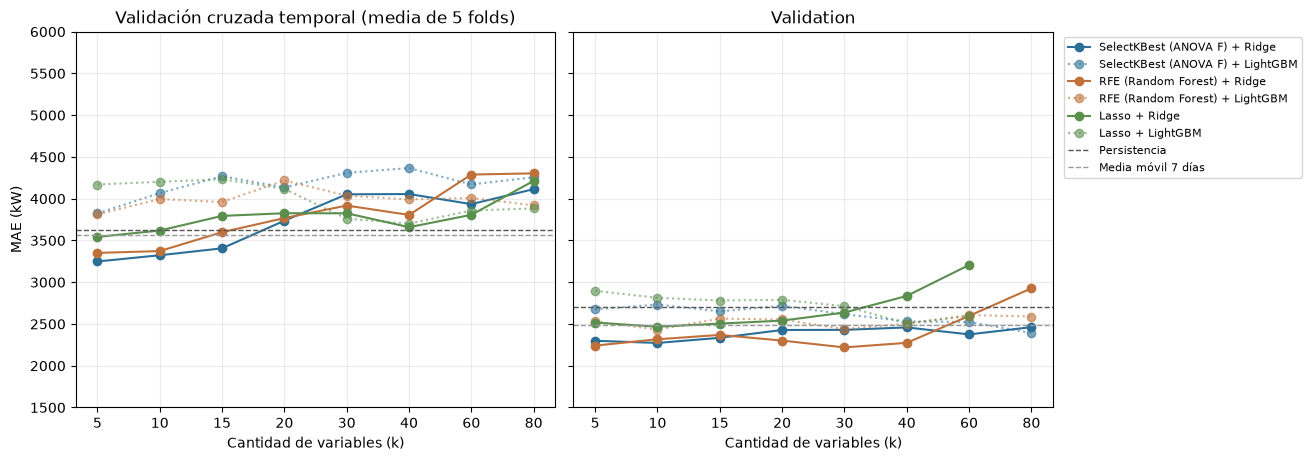

In [6]:
fig, ejes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True, layout='constrained')
colores = {'SelectKBest (ANOVA F)': '#2a6f97', 'RFE (Random Forest)': '#c0703a', 'Lasso': '#5a8f4e'}
for eje, (titulo, datos) in zip(ejes, [('Validación cruzada temporal (media de 5 folds)', resumen_cv['mean']),
                                       ('Validation', resumen_val)]):
    for metodo, color in colores.items():
        serie = datos.loc[metodo].reindex(KS)
        posiciones = range(len(KS))
        eje.plot(posiciones, serie['Ridge'], marker='o', color=color, label=f'{metodo} + Ridge')
        eje.plot(posiciones, serie['LightGBM'], marker='o', linestyle=':', color=color, alpha=.6,
                 label=f'{metodo} + LightGBM')
    referencia = baselines.iloc[:-1].mean() if titulo.startswith('Validación') else baselines.loc['Validation']
    eje.axhline(referencia['Persistencia'], color='#555', linestyle='--', linewidth=1, label='Persistencia')
    eje.axhline(referencia['Media móvil 7 días'], color='#999', linestyle='--', linewidth=1, label='Media móvil 7 días')
    eje.set(title=titulo, xlabel='Cantidad de variables (k)', xticks=range(len(KS)), xticklabels=KS)
    eje.grid(alpha=.25)
ejes[0].set_ylabel('MAE (kW)')
ejes[0].set_ylim(1500, 6000)
ejes[1].legend(fontsize=8, loc='upper left', bbox_to_anchor=(1.01, 1))
plt.show()

### Estabilidad de la selección

Para cada método y cada k comparamos los conjuntos elegidos en los cinco folds de a pares y promediamos el índice de Jaccard (variables en común sobre variables en total).

In [7]:
estabilidad = []
for metodo in METODOS:
    for k in [5, 10, 20, 30]:
        conjuntos = [set(orden[metodo][:k]) for orden in ordenes_por_fold if len(orden[metodo]) >= k]
        pares = [len(a & b) / len(a | b) for i, a in enumerate(conjuntos) for b in conjuntos[i + 1:]]
        estabilidad.append({'metodo': metodo, 'k': k, 'Jaccard medio': np.mean(pares) if pares else np.nan})
estabilidad = pd.DataFrame(estabilidad)
display(estabilidad.pivot(index='metodo', columns='k', values='Jaccard medio').round(2))

k,5,10,20,30
metodo,,,,
Lasso,0.33,0.26,0.34,0.38
RFE (Random Forest),0.64,0.41,0.26,0.27
SelectKBest (ANOVA F),0.70,0.62,0.51,0.53


### Variables elegidas con Train completo

In [8]:
top = pd.DataFrame({metodo: pd.Series(orden[:15]) for metodo, orden in ordenes_train.items()})
top.index = top.index + 1
display(top)
coincidencias = {f'{a} y {b}': len(set(ordenes_train[a][:10]) & set(ordenes_train[b][:10]))
                 for i, a in enumerate(METODOS) for b in METODOS[i + 1:]}
print('Variables en común entre los top 10:', coincidencias)

,SelectKBest (ANOVA F),RFE (Random Forest),Lasso
1,Frio (Kw) (Consolidado EE),Frio (Kw) (Consolidado EE),Frio (Kw) (Consolidado EE)
2,Frio (Kw) (Consolidado EE)_MediaMov_7d,Frio (Kw) (Consolidado EE)_MediaMov_7d,KW Secador Kaeser (Totalizadores Energia)
3,KW Trafo 11 (Totalizadores Energia),KW Laboratorio (Totalizadores Energia),Vapor Servicio (Kg) (Consolidado GasVapor)_Med...
4,Frio (Kw) (Consolidado EE)_Lag_7,ET Bodega/Hl (Consolidado KPI)_MediaMov_7d,Hl Cerveza Filtrada (Consolidado Produccion)_M...
5,Frio (Kw) (Consolidado EE)_Lag_1,HL Mosto Tecate (Totalizadores Produccion)_Med...,Vapor Servicio (Kg) (Consolidado GasVapor)
6,ET Bodega/Hl (Consolidado KPI)_MediaMov_7d,FC Centec II (Totalizadores Agua)_MediaMov_7d,KW Cond 5. 6 y 9 (Totalizadores Energia)
7,KW Trafo 11 (Totalizadores Energia)_MediaMov_7d,Kw Molino (Totalizadores Energia),KW Trafo 11 (Totalizadores Energia)_MediaMov_7d
8,Agua Planta (Hl) (Consolidado Agua),Bodega (Kw) (Consolidado EE)_MediaMov_7d,Aire Envasado (M3) (Consolidado Aire)_MediaMov_7d
9,KW Cond 5. 6 y 9 (Totalizadores Energia),ET Cocina/Hl (Consolidado KPI)_Lag_1,Totalizador_Filtracion (Totalizadores CO2)_Lag_1
10,FC Centec II (Totalizadores Agua)_MediaMov_7d,ET Servicios (Mj) (Consolidado GasVapor)_Media...,Nivel Tk Restos Lev (Totalizadores Produccion)


Variables en común entre los top 10: {'SelectKBest (ANOVA F) y RFE (Random Forest)': 4, 'SelectKBest (ANOVA F) y Lasso': 3, 'RFE (Random Forest) y Lasso': 1}


## 5. Criterios de elección: SelectKBest con ANOVA F y k = 10

Elegimos el método con cuatro criterios, en este orden. Los números son los de las tablas anteriores (MAE en kW, con Ridge salvo que se indique otra cosa).

**1. Error en la validación cruzada temporal (criterio principal).** Es la medida más confiable porque promedia cinco tramos de tiempo distintos y la consigna permite elegir con `TimeSeriesSplit` sobre Train. SelectKBest obtiene el menor MAE de todas las combinaciones: 3.248 con k = 5 y 3.323 con k = 10. RFE queda en 3.351 (k = 5) y Lasso en 3.542 (k = 5). Usar las casi 500 variables da 8.173 con Ridge y 3.856 con LightGBM.

**2. Confirmación en Validation.** Con la selección ajustada sobre Train completo, SelectKBest k = 10 da 2.273 y RFE da entre 2.220 (k = 30) y 2.241 (k = 5). La diferencia, de 30 a 50 kW (1 a 2 %), es mucho menor que la variación entre folds de la validación cruzada (desvío de 300 a 450 kW), así que en Validation los dos métodos quedan empatados. Lasso queda atrás: 2.467 en su mejor k y 3.614 con las 77 variables que elige su propio alpha.

**3. Estabilidad.** SelectKBest repite el 62 % de sus 10 variables entre folds (Jaccard 0,62), contra 0,41 de RFE y 0,26 de Lasso. Un método inestable elige variables distintas con cada tramo de datos, así que su buen resultado en Validation depende en parte del azar. RFE lo muestra: rinde bien en Validation con k = 5 y con k = 30 eligiendo conjuntos distintos, y en la validación cruzada empeora a medida que suma variables. Lasso es todavía más variable: su alpha cambia de un fold a otro y termina eligiendo entre 14 y 105 variables.

**4. Coherencia con el EDA y simplicidad.** Las 10 variables de SelectKBest son las que el EDA ya había señalado: el Frío del día con sus rezagos de 1 y 7 días y su media móvil de 7 días, más los consumos de la planta más correlacionados con el target (Trafo 11, agua de planta, condensadores 5, 6 y 9). RFE y Lasso incorporan variables sin una relación física clara con el frío, como el laboratorio, el molino o el secador de aire. Además, SelectKBest es el más simple de explicar y de reproducir: un estadístico por variable, sin modelo intermedio.

**Por qué k = 10.** Con k = 5 y k = 10 el resultado es prácticamente el mismo: k = 5 gana por 75 kW en la validación cruzada y k = 10 gana por 26 kW en Validation, ambos dentro de la variación entre folds. Elegimos 10 porque suma variables de producción y consumo de la planta a las del propio Frío, sin perder simplicidad: un conjunto manejable e informativo, como pide la consigna.

**Limitación conocida.** El ANOVA F evalúa cada variable por separado y puede elegir variables redundantes entre sí (por ejemplo, el Frío del día y su media móvil). El pipeline mitiga esto porque antes elimina los pares con |r| ≥ 0,90. Ridge maneja bien la correlación que queda.

**Comparación con los baselines.** Con estas 10 variables, Ridge baja el MAE de Validation a 2.273 kW, frente a 2.701 de la persistencia y 2.484 de la media móvil de 7 días: un 8,5 % mejor que el mejor baseline. En la validación cruzada el mejor baseline también es la media móvil (3.564) y la mejora es del 7 % con k = 10 y del 9 % con k = 5. La selección reduce mucho el error respecto de usar todas las variables, pero todavía no alcanza el 10 % de mejora que plantea la consigna: el próximo paso es volver a optimizar los hiperparámetros con el conjunto reducido.

## 6. Registro de la comparación

Guardamos todos los resultados en `results/seleccion_variables/` para que la decisión quede trazable:

- `resultados.csv`: MAE de cada método, k, modelo y evaluación (cada fold y Validation).
- `baselines.csv` y `estabilidad.csv`.
- `seleccion_final.json`: método elegido, k, variables seleccionadas con Train completo y las de los otros métodos.

In [9]:
K_ELEGIDO = 10
variables_finales = ordenes_train['SelectKBest (ANOVA F)'][:K_ELEGIDO]
puntaje_f, p_valor = f_regression(X_tr[variables_finales], y_train)

resultados.to_csv(CARPETA_RESULTADOS / 'resultados.csv', index=False)
baselines.to_csv(CARPETA_RESULTADOS / 'baselines.csv')
estabilidad.to_csv(CARPETA_RESULTADOS / 'estabilidad.csv', index=False)
registro = {
    'fecha': datetime.now().strftime('%Y-%m-%d %H:%M:%S'),
    'metodo_elegido': 'SelectKBest(f_regression)',
    'k': K_ELEGIDO,
    'ajustado_con': 'Train',
    'variables_seleccionadas': variables_finales,
    'metodos_comparados': {metodo: orden[:K_ELEGIDO] for metodo, orden in ordenes_train.items()},
    'lasso_alpha_train': float(alpha_train),
    'lasso_variables_no_nulas_train': len(ordenes_train['Lasso']),
}
(CARPETA_RESULTADOS / 'seleccion_final.json').write_text(json.dumps(registro, indent=2, ensure_ascii=False) + '\n',
                                                          encoding='utf-8')
display(pd.DataFrame({'F': puntaje_f.round(0), 'p': p_valor}, index=variables_finales))
print(f'Registro guardado en {CARPETA_RESULTADOS.relative_to(RAIZ).as_posix()}/')

,F,p
Frio (Kw) (Consolidado EE),1991.0,1.871073e-215
Frio (Kw) (Consolidado EE)_MediaMov_7d,1618.0,3.030169e-191
KW Trafo 11 (Totalizadores Energia),946.0,4.567050e-136
Frio (Kw) (Consolidado EE)_Lag_7,916.0,4.061142e-133
Frio (Kw) (Consolidado EE)_Lag_1,914.0,6.857765e-133
ET Bodega/Hl (Consolidado KPI)_MediaMov_7d,912.0,1.198376e-132
KW Trafo 11 (Totalizadores Energia)_MediaMov_7d,903.0,8.543007e-132
Agua Planta (Hl) (Consolidado Agua),782.0,3.193254e-119
KW Cond 5. 6 y 9 (Totalizadores Energia),701.0,3.155352e-110
FC Centec II (Totalizadores Agua)_MediaMov_7d,672.0,5.810334e-107


Registro guardado en results/seleccion_variables/
